# High-dim limit of metric MDS under distance concentration

In [1]:
import numpy as np
import pylab as plt
from sklearn.manifold import MDS

plt.style.use('mpl_style.txt')

In [2]:
n = 10_000
D = np.ones((n, n))
np.fill_diagonal(D, 0)

%time Z = MDS(n_init=1, init="random", verbose=5, metric="precomputed").fit_transform(D)

Iteration 0, stress 8968762.9779
Iteration 1, stress 8909634.9096
Iteration 2, stress 8888200.8342
Iteration 3, stress 8879241.7928
Iteration 4, stress 8875272.9830
Iteration 5, stress 8873458.6395
Iteration 6, stress 8872609.2491
Iteration 7, stress 8872201.8477
Iteration 8, stress 8872000.5181
Iteration 9, stress 8871896.9665
Iteration 10, stress 8871840.7627
Iteration 11, stress 8871808.0894
Convergence criterion reached (iteration 11).
CPU times: user 59.2 s, sys: 32.8 s, total: 1min 31s
Wall time: 38.6 s


In [80]:
# %%time

# RRs = []

# for rep in range(10):
#     print(".", end="", flush=True)
#     ZZ = MDS(n_init=1, init="random", metric="precomputed").fit_transform(D)
#     RR = np.sqrt(np.sum(ZZ ** 2, axis=1))
#     RRs = np.concatenate((RRs, RR))

# print("")

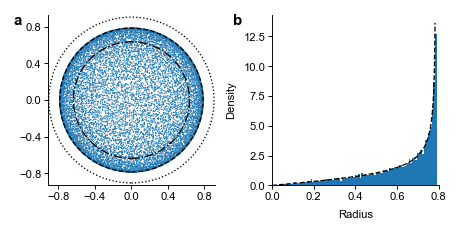

In [3]:
fig = plt.figure(figsize=(3.25, 1.6), layout="constrained")

plt.subplot(121)
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=2, ec="none", rasterized=True)
plt.xticks(np.arange(-.8, .81, .4))
plt.yticks(np.arange(-.8, .81, .4))

c = plt.Circle((0, 0), np.pi / 4, facecolor="none", edgecolor="k", linestyle='--', lw=.7)
plt.gca().add_patch(c)
c = plt.Circle((0, 0), 2 / np.pi, facecolor="none", edgecolor="k", linestyle='-.', lw=.7)
plt.gca().add_patch(c)
# c = plt.Circle((0, 0), 45 * np.pi / 128, facecolor="none", edgecolor="k", linestyle=':', lw=.6)
# plt.gca().add_patch(c)
c = plt.Circle((0, 0), 128 / np.pi / 45, facecolor="none", edgecolor="k", linestyle=':', lw=.7)
plt.gca().add_patch(c)

plt.subplot(122)
rrr = np.sqrt(np.sum(Z ** 2, axis=1))
plt.hist(rrr, bins=100, density=True);
plt.xlim([0, .8])
plt.xlabel("Radius")
plt.ylabel("Density")

x = np.arange(0, np.pi/4 - 0.003, 0.001)
y = 4 * x / (np.pi * np.sqrt((np.pi / 4) ** 2 - x ** 2))
plt.plot(x, y, 'k--', lw=.7)

fig.text(.00, .93, "a", fontweight="bold", fontsize=8)
fig.text(.50, .93, "b", fontweight="bold", fontsize=8)

fig.savefig("figures/limit.png", dpi=300)
fig.savefig("figures/limit.pdf", dpi=300)

In [82]:
from sklearn.metrics import pairwise_distances

dd = pairwise_distances(Z)[np.triu_indices(Z.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 0.823, std 0.382, MSE 0.177


In [83]:
R = Z / np.sqrt(np.sum(Z**2, axis=1, keepdims=True)) * np.pi / 4

dd = pairwise_distances(R)[np.triu_indices(Z.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 1.000, std 0.483, MSE 0.234


In [84]:
R = Z / np.sqrt(np.sum(Z**2, axis=1, keepdims=True)) * 2 / np.pi

dd = pairwise_distances(R)[np.triu_indices(Z.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 0.811, std 0.392, MSE 0.189


In [85]:
D = (np.random.rand(*Z.shape) - .5) * 2
r = np.sqrt(np.sum(D**2, axis=1))
D = D[r < 128 / 45 / np.pi]

dd = pairwise_distances(D)[np.triu_indices(D.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 0.822, std 0.385, MSE 0.180
